In [2]:
import pandas as pd
import requests
import numpy as np

import json
from google.oauth2 import service_account
from google.auth.transport.requests import Request
import base64


import io
from IPython.display import display,clear_output,Image, Audio
import ipywidgets as widgets
import sounddevice as sd
import soundfile as sf

In [3]:
# #use earpod for sound output
# sd._terminate(); sd._initialize()
# print(sd.query_devices())

In [4]:
game_df = pd.read_csv('data/sound_img_list.csv')
display(game_df)

,name,location,img_url
0,bear,Sound/bear.mp3,https://commons.wikimedia.org/wiki/Special:Fil...
1,cat,Sound/cat.mp3,https://commons.wikimedia.org/wiki/Special:Fil...
2,chicken,Sound/chicken.mp3,https://commons.wikimedia.org/wiki/Special:Fil...
3,chicks,Sound/chicks.mp3,https://commons.wikimedia.org/wiki/Special:Fil...
4,cow,Sound/cow.mp3,https://commons.wikimedia.org/wiki/Special:Fil...
5,dog,Sound/dog.mp3,https://commons.wikimedia.org/wiki/Special:Fil...
6,donkey,Sound/donkey.mp3,https://commons.wikimedia.org/wiki/Special:Fil...
7,duck,Sound/duck.mp3,https://commons.wikimedia.org/wiki/Special:Fil...
8,elephant,Sound/elephant.mp3,https://commons.wikimedia.org/wiki/Special:Fil...
9,frog,Sound/frog.mp3,https://commons.wikimedia.org/wiki/Special:Fil...


In [9]:
def stop_sound_button(i):
    stop_button=widgets.Button(
        description ='stop animal sound',
         disabled = False,
         button_style='info',
    )
    def clear_output():
        display.clear_output(wait=True)
    stop_button.on_click(clear_output)
    display(stop_button)

In [10]:
stop_sound_button(0)

Button(button_style='info', description='stop animal sound', style=ButtonStyle())

In [16]:
creds = service_account.Credentials.from_service_account_file(
    "keys/service.json",
    scopes=["https://www.googleapis.com/auth/cloud-platform"],
)
creds.refresh(Request())
token = creds.token

with open('keys/keys.json', 'r') as f:
    keys = json.load(f)


def get_audio(animal):

    url = "https://aiplatform.googleapis.com/v1beta1/projects/wpp-cto-smartprod-sandbox/locations/global/interactions"

    payload = {
      "model": "lyria-3-clip-preview",
      "input": [
        {
          "type": "text",
          "text": f"song about {animal} sound"
        }
      ]
    }
    headers = {
        "Authorization": f"Bearer {token}",
        "Content-Type": "application/json",
    }

    response = requests.post(url, headers=headers, json=payload)
    # print(response)
    print(response.text)
    # print(response.status_code)
    # print(response.headers)
    data = response.json()
    bytedata = data["outputs"][2]["data"]
    return base64.b64decode(bytedata)

In [17]:
# def play_announcement(text):
#     try:
#         mp3 = get_audio(text)
#         display(Audio(mp3, autoplay=True))
#     except Exception as e:
#         print(f"(Couldn't play audio: {e})")

In [25]:
import threading
from IPython.display import Audio

_audio_cache = {}

def play_announcement(text, out):
    def worker():
        try:
            if text not in _audio_cache:
                _audio_cache[text] = get_audio(text)
            out.append_display_data(Audio(_audio_cache[text], autoplay=True))
        except Exception as e:
            out.append_stdout(f"(Couldn't play audio: {e})\n")
    threading.Thread(target=worker, daemon=True).start()

In [26]:
ui_imag_df = pd.read_csv('data/UI_img_list.csv')
display(ui_imag_df)

,name,location
0,farm,Image/farm_bkg.png
1,Luma,Image/Luma.png
2,Ray,Image/Ray.png


In [27]:
# The play button plays that stored animal’s sound.
# The options are built from that stored animal plus two different wrong ones, shuffled.
# The checker compares the clicked name to that stored name, not to a function call.

In [32]:
def sound_selection():
    output = widgets.Output()

    choices = game_df.drop_duplicates('name').sample(5)
    correct_answer = choices.sample().iloc[0]

    sound_selection_buttons = widgets.ToggleButtons(
        options=list(choices['name']),
        value=None,
        description='Choose the animal that makes the sound:',
        button_style=''
    )

    play_button = widgets.Button(
        description='play animal sound',
        button_style='info'
    )

    def play_sound(b):
        with output:
            output.clear_output(wait=True)
            display(Audio(correct_answer['location'], autoplay=True))

    @output.capture(clear_output=True)
    def button_clicker(change):
        if change.new == correct_answer['name']:
            print('Correct! Wait for a fun theme song to play')
            play_announcement(f"The sound of {correct_answer['name']} ", output)

        else:
            print('wrong')

    play_button.on_click(play_sound)
    sound_selection_buttons.observe(button_clicker, names='value')
    display(widgets.VBox([play_button, sound_selection_buttons, output]))
    return correct_answer['name']

answer = sound_selection()

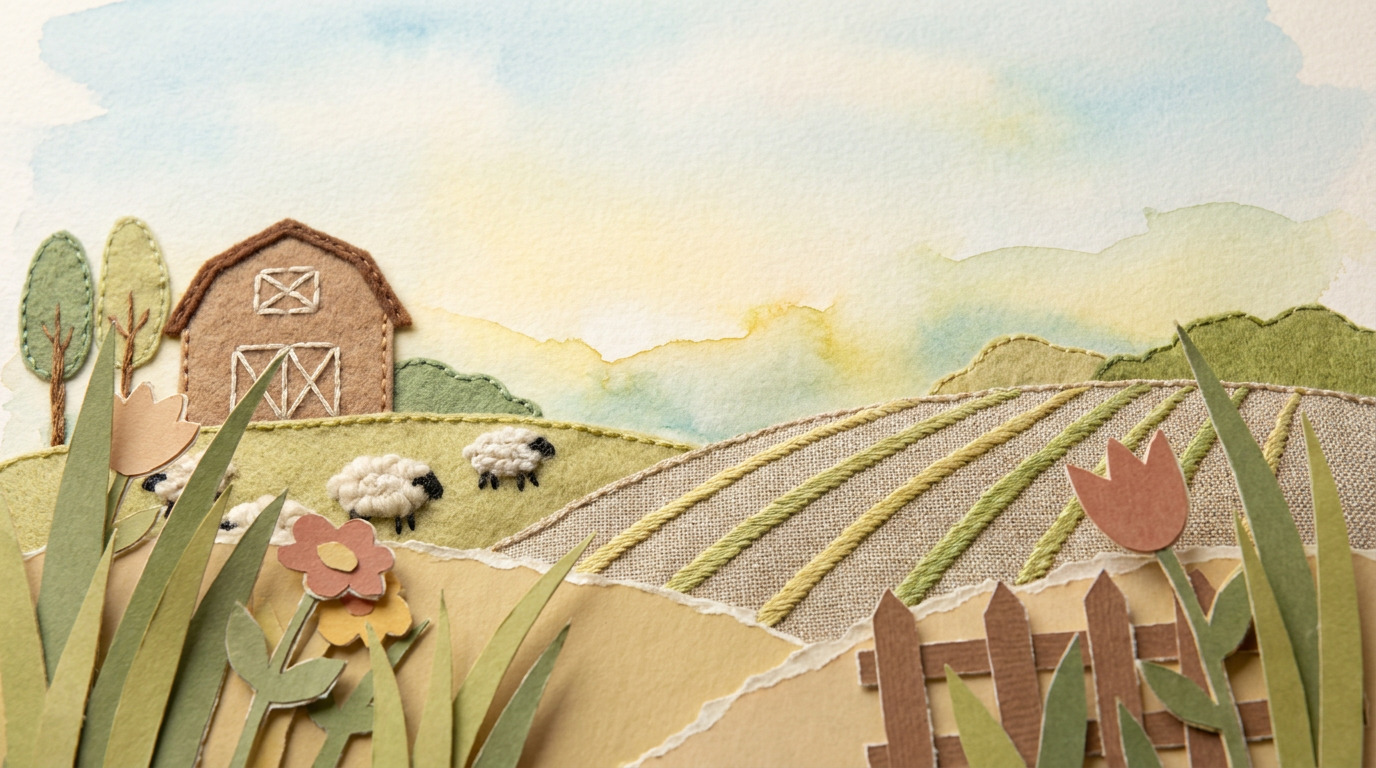

Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x08\xe0\x00\x00\x08p\x08\x06\x00\x00\x00\x8eg\xd3\x8…

Button(button_style='info', description='Start Game!', style=ButtonStyle())

Output()

Button(button_style='primary', description='Back to Menu', layout=Layout(display='none'), style=ButtonStyle())

In [31]:
def menu_state():
    start_game_button = widgets.Button(
        description='Start Game!',
        button_style='info'
    )

    
    fram_bkg = ui_imag_df.location.iloc[0]
    display(Image(filename=fram_bkg,width=500))
    
    luma_img = widgets.Image.from_file(ui_imag_df.location.iloc[1])
    luma_img.width = 200



    
    
    back_to_menu_btn = widgets.Button(
        description='Back to Menu',
        button_style='primary'
    )
    back_to_menu_btn.layout.display = 'none'
    output = widgets.Output()
    @output.capture(clear_output =True)
   
    def start_game(b):
        start_game_button.layout.display = 'none'
        animal=sound_selection()
        back_to_menu_btn.layout.display = ''
        luma_img.layout.display = 'none'


    def restart_game(b):
        output.clear_output()
        start_game_button.layout.display = ''
        back_to_menu_btn.layout.display = 'none'   
        luma_img.layout.display = ''

    def 


        
    back_to_menu_btn.on_click(restart_game)
    start_game_button.on_click(start_game)
    display(luma_img,start_game_button,output,back_to_menu_btn)

menu_state()